# Local cell density and the OneCut1 perturbation effect

Soma and neurite morphology comparison between OneCut1-perturbed and negative-control cells, using the same
CellProfiler QC and BFP-positive gating as the primary comparison, to test whether the morphology differences
depend on local cell crowding.

Local density is defined as the number of other QC-passed cells within a 150 px radius (about 3 cell diameters,
based on the median cell diameter and nearest-neighbor spacing in this dataset) of a cell's centroid, within the
same field of view, independent of BFP status. Cells are then progressively filtered by excluding the densest X%
(threshold set on the pooled distribution across both conditions) and the comparison is repeated at each
threshold.

In [1]:
import sqlite3, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, mannwhitneyu
from scipy.spatial import cKDTree
from sklearn.mixture import GaussianMixture
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", "{:.4g}".format)

OUT_DIR = "density_filtering/"

DB_TREATMENT = "path/to/file/treatment_DefaultDB.db"
DB_CONTROL = "path/to/file/negative_control_DefaultDB.db"

bfp_col, ecc_col = "soma_Intensity_MeanIntensity_BFP", "soma_AreaShape_Eccentricity"
METRICS = {
    "AreaShape_Area": "soma_AreaShape_Area",
    "AreaShape_Solidity": "soma_AreaShape_Solidity",
    "AreaShape_Compactness": "soma_AreaShape_Compactness",
    "Skeleton_TotalLength_neurite": "soma_ObjectSkeleton_TotalObjectSkeletonLength_neurite_binary",
    "Neighbors_Number_neurite_Exp": "soma_Neighbors_NumberOfNeighbors_neurite_Expanded",
    "Neighbors_PctTouching_neurite_Exp": "soma_Neighbors_PercentTouching_neurite_Expanded",
}
METRIC_SHORT = {
    "AreaShape_Area": "Area", "AreaShape_Solidity": "Solidity", "AreaShape_Compactness": "Compactness",
    "Skeleton_TotalLength_neurite": "NeuriteLength", "Neighbors_Number_neurite_Exp": "NeuriteNumber",
    "Neighbors_PctTouching_neurite_Exp": "NeuriteTouchingPercent",
}
METRICS_3 = ["AreaShape_Area", "AreaShape_Solidity", "Skeleton_TotalLength_neurite"]

ALPHA = 0.05
POSTERIOR_CUTOFF = 0.9
NEIGHBOR_RADIUS_PX = 150
TREATMENT_KEY = "OneCut1"
GROUPS = [TREATMENT_KEY, "Ctrl"]
LABEL = {TREATMENT_KEY: "OneCut1", "Ctrl": "NegativeControl"}
COLOR = {TREATMENT_KEY: "#4c72b0", "Ctrl": "#dd8452"}

def savefig(fig, name):
    fig.savefig(f"{OUT_DIR}{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"{OUT_DIR}{name}.svg", bbox_inches="tight")

## Load cell morphology metrics and BFP intensity

In [2]:
def load(path, experiment_filter):
    conn = sqlite3.connect(f"file:{path}?mode=ro", uri=True)
    soma_cols = ["ImageNumber", bfp_col, ecc_col, "soma_AreaShape_Center_X", "soma_AreaShape_Center_Y"] + list(METRICS.values())
    soma = pd.read_sql_query(f"SELECT {', '.join(soma_cols)} FROM Per_soma", conn)
    img = pd.read_sql_query("SELECT ImageNumber, Image_Metadata_Experiment AS experiment FROM Per_Image", conn)
    conn.close()
    df = soma.merge(img, on="ImageNumber", how="left", validate="many_to_one")
    return df[df["experiment"] == experiment_filter].copy()

treatment = load(DB_TREATMENT, "BF_BFP"); treatment["group"] = TREATMENT_KEY
control = load(DB_CONTROL, "negative_control_gRNA_100K"); control["group"] = "Ctrl"
cells = pd.concat([treatment, control], ignore_index=True)
cells = cells.rename(columns={v: k for k, v in METRICS.items()})
cells = cells.rename(columns={"soma_AreaShape_Center_X": "x", "soma_AreaShape_Center_Y": "y"})

qc = cells[(cells["AreaShape_Area"] > 1000) & (cells[ecc_col] > 0.4)].copy()
print(f"QC: {len(cells):,} -> {len(qc):,} cells")
print(qc.groupby("group").size().rename("cells (post-QC, all BFP status)"))

QC: 461,327 -> 363,569 cells
group
Ctrl       140649
OneCut1    222920
Name: cells (post-QC, all BFP status), dtype: int64


## Local density: neighbor count within a 150 px radius, per field of view

Every QC-passed cell counts as a potential neighbor regardless of its own BFP status, since local density is a property of how crowded a field of view is, not of which cells are perturbed.

In [3]:
qc["neighbor_count"] = 0
for (grp, image_number), sub in qc.groupby(["group", "ImageNumber"]):
    # group by (condition, field of view): field-of-view numbering is assigned independently per source
    # database, so the same number can refer to unrelated physical tiles in different conditions
    if len(sub) < 2:
        continue
    pts = sub[["x", "y"]].to_numpy()
    tree = cKDTree(pts)
    counts = tree.query_ball_point(pts, r=NEIGHBOR_RADIUS_PX, return_length=True) - 1
    qc.loc[sub.index, "neighbor_count"] = counts

print(qc.groupby("group")["neighbor_count"].describe()[["mean", "std", "min", "25%", "50%", "75%", "max"]])

         mean   std  min  25%  50%  75%  max
group                                       
Ctrl    5.338 4.312    0    2    4    7   36
OneCut1 5.804 3.717    0    3    5    8   36


## BFP-positive gating

Cells are called perturbed if their BFP intensity posterior probability exceeds 0.9 under a per-condition two-component Gaussian mixture model on log10(BFP intensity).

In [4]:
def fit_gmm_posterior(vals):
    log_v = np.log10(vals.to_numpy()).reshape(-1, 1)
    gmm = GaussianMixture(n_components=2, random_state=0, n_init=5).fit(log_v)
    pos_idx = int(np.argmax(gmm.means_.ravel()))
    return gmm.predict_proba(log_v)[:, pos_idx]

qc["post_pos"] = np.nan
for g, sub in qc.groupby("group"):
    qc.loc[sub.index, "post_pos"] = fit_gmm_posterior(sub[bfp_col])
qc["perturbed"] = qc["post_pos"] > POSTERIOR_CUTOFF

for g in GROUPS:
    sub = qc[qc.group == g]
    n_pos = int(sub["perturbed"].sum())
    print(f"{LABEL[g]}: {n_pos:,} / {len(sub):,} ({100*n_pos/len(sub):.2f}%) BFP-positive at posterior>{POSTERIOR_CUTOFF}")

pert = qc[qc["perturbed"]].copy()

OneCut1: 21,690 / 222,920 (9.73%) BFP-positive at posterior>0.9
NegativeControl: 19,490 / 140,649 (13.86%) BFP-positive at posterior>0.9


In [5]:
def compare(a, b, label):
    _, t_p = ttest_ind(a, b, equal_var=True)
    _, u_p = mannwhitneyu(a, b, alternative="two-sided")
    return {"metric": label, "n_treatment": len(a), "n_control": len(b), "mean_treatment": a.mean(), "mean_control": b.mean(),
            "diff": a.mean() - b.mean(), "std_effect": (a.mean() - b.mean()) / np.concatenate([a, b]).std(),
            "t_p_raw": t_p, "u_p_raw": u_p}

def finalize(records):
    r = pd.DataFrame(records)
    r["t_p_adj"] = multipletests(r["t_p_raw"], alpha=ALPHA, method="fdr_bh")[1]
    r["u_p_adj"] = multipletests(r["u_p_raw"], alpha=ALPHA, method="fdr_bh")[1]
    r["significant"] = (r["t_p_adj"] < ALPHA) | (r["u_p_adj"] < ALPHA)
    r["direction"] = np.where(r["mean_treatment"] > r["mean_control"], f"{TREATMENT_KEY} > control", f"control > {TREATMENT_KEY}")
    return r

## Densest-cell exclusion sweep, all 6 metrics

At each threshold, cells with `neighbor_count` above the corresponding percentile of the pooled (both-condition) BFP-positive distribution are dropped, and the comparison is rerun on the remainder.

In [6]:
exclude_pcts = [0, 5, 10, 15, 20, 30, 40, 50, 60, 70]
sweep_rows = []
for ex_pct in exclude_pcts:
    keep_pct = 100 - ex_pct
    cutoff = pert["neighbor_count"].quantile(keep_pct / 100) if keep_pct < 100 else pert["neighbor_count"].max()
    sub = pert[pert["neighbor_count"] <= cutoff]
    t_df = sub[sub.group == TREATMENT_KEY]
    c_df = sub[sub.group == "Ctrl"]
    r = finalize([compare(t_df[m].dropna().to_numpy(), c_df[m].dropna().to_numpy(), m) for m in METRICS])
    r["excluded_pct"] = ex_pct
    r["neighbor_count_cutoff"] = cutoff
    r["n_treatment"] = len(t_df)
    r["n_control"] = len(c_df)
    sweep_rows.append(r)

sweep_df = pd.concat(sweep_rows, ignore_index=True)

print("u_p_adj (rank test) by excluded-densest-% threshold, one row per metric:")
pivot_u = sweep_df.pivot(index="metric", columns="excluded_pct", values="u_p_adj").loc[list(METRICS)]
display(pivot_u.style.format("{:.3g}"))

print("\ndirection by excluded-densest-% threshold:")
pivot_dir = sweep_df.pivot(index="metric", columns="excluded_pct", values="direction").loc[list(METRICS)]
display(pivot_dir)

print("\nn kept (treatment, control) by threshold:")
display(sweep_df.drop_duplicates("excluded_pct").set_index("excluded_pct")[["n_treatment", "n_control", "neighbor_count_cutoff"]])

u_p_adj (rank test) by excluded-densest-% threshold, one row per metric:


excluded_pct,0,5,10,15,20,30,40,50,60,70
metric,,,,,,,,,,
AreaShape_Area,7.52e-14,1.79e-10,7.96e-07,3.85e-06,0.000141,0.000391,0.00579,0.0371,0.375,0.641
AreaShape_Solidity,1.1e-69,3.46e-71,1.7e-79,2.07e-81,2.49e-82,3.21e-80,6.73e-80,8.49e-82,6.29e-74,2.53e-64
AreaShape_Compactness,8.23e-137,3.58e-137,6.7e-144,1.05e-144,2.89e-144,1.1e-139,1.6e-130,5.37e-127,1.25e-110,6.01e-89
Skeleton_TotalLength_neurite,3.84e-13,9.88e-12,1.21e-07,3.85e-06,0.000141,0.000887,0.0106,0.111,0.717,0.641
Neighbors_Number_neurite_Exp,7.33e-69,3.9e-66,6.14e-51,3.76e-42,3.58e-31,4.72e-23,3.38e-11,1.29e-05,0.125,0.641
Neighbors_PctTouching_neurite_Exp,0,0,0,0,0,0,9.5e-279,3.58e-216,9.24e-143,1.09e-80



direction by excluded-densest-% threshold:


excluded_pct,0,5,10,15,20,30,40,50,60,70
metric,,,,,,,,,,
AreaShape_Area,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control
AreaShape_Solidity,control > OneCut1,control > OneCut1,control > OneCut1,control > OneCut1,control > OneCut1,control > OneCut1,control > OneCut1,control > OneCut1,control > OneCut1,control > OneCut1
AreaShape_Compactness,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control
Skeleton_TotalLength_neurite,OneCut1 > control,control > OneCut1,control > OneCut1,control > OneCut1,control > OneCut1,control > OneCut1,control > OneCut1,control > OneCut1,control > OneCut1,control > OneCut1
Neighbors_Number_neurite_Exp,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control
Neighbors_PctTouching_neurite_Exp,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control,OneCut1 > control



n kept (treatment, control) by threshold:


,n_treatment,n_control,neighbor_count_cutoff
excluded_pct,,,
0,21690,19490,36
5,20830,18590,18
10,19969,17518,14
15,19136,16684,12
20,17679,15389,10
30,16568,14506,9
40,13704,12276,7
50,11890,10820,6
60,9713,9236,5


## NeuriteLength: mean- vs. median-based effect across the exclusion sweep

Mean-based (t-test) and median-based (Mann-Whitney) effect size and p-value for NeuriteLength specifically, at each exclusion threshold, shown unadjusted since this is a single-metric diagnostic rather than the multi-metric comparison above.

In [7]:
exclude_pcts_nl = [0, 5, 10, 15, 20, 30, 40, 50, 60, 70]
nl_rows = []
for ex_pct in exclude_pcts_nl:
    keep_pct = 100 - ex_pct
    cutoff = pert["neighbor_count"].quantile(keep_pct / 100) if keep_pct < 100 else pert["neighbor_count"].max()
    sub = pert[pert["neighbor_count"] <= cutoff]
    t = sub[sub.group == TREATMENT_KEY]["Skeleton_TotalLength_neurite"].dropna().to_numpy()
    c = sub[sub.group == "Ctrl"]["Skeleton_TotalLength_neurite"].dropna().to_numpy()
    _, t_p = ttest_ind(t, c, equal_var=True)
    _, u_p = mannwhitneyu(t, c, alternative="two-sided")
    mean_pct = 100 * (t.mean() - c.mean()) / c.mean()
    med_t, med_c = np.median(t), np.median(c)
    median_pct = 100 * (med_t - med_c) / med_c
    nl_rows.append({"excluded_pct": ex_pct, "n_treatment": len(t), "n_control": len(c),
                     "mean_pct_change": mean_pct, "t_p_raw": t_p,
                     "median_pct_change": median_pct, "u_p_raw": u_p})
nl_df = pd.DataFrame(nl_rows)
nl_df["mean_positive_sig"] = (nl_df["mean_pct_change"] > 0) & (nl_df["t_p_raw"] < ALPHA)
nl_df["median_positive_sig"] = (nl_df["median_pct_change"] > 0) & (nl_df["u_p_raw"] < ALPHA)
display(nl_df[["excluded_pct", "n_treatment", "n_control", "mean_pct_change", "t_p_raw", "mean_positive_sig",
                "median_pct_change", "u_p_raw", "median_positive_sig"]])

,excluded_pct,n_treatment,n_control,mean_pct_change,t_p_raw,mean_positive_sig,median_pct_change,u_p_raw,median_positive_sig
0,0,21690,19490,0.2468,0.8581,False,28.26,3.842e-13,True
1,5,20830,18590,-0.3703,0.7864,False,25.08,8.234e-12,True
2,10,19969,17518,-1.844,0.1744,False,20.76,1.007e-07,True
3,15,19136,16684,-2.479,0.06814,False,18.11,3.638e-06,True
4,20,17679,15389,-3.07,0.02562,False,16.4,0.0001414,True
5,30,16568,14506,-3.298,0.0181,False,14.62,0.0008869,True
6,40,13704,12276,-3.315,0.02508,False,11.97,0.01062,True
7,50,11890,10820,-4.01,0.009685,False,8.896,0.1107,False
8,60,9713,9236,-4.753,0.004373,False,4.421,0.7166,False
9,70,7375,7440,-5.381,0.00405,False,0.158,0.61,False


## Area, Solidity, NeuriteLength: median % change and rank-test p-value across the exclusion sweep

BH correction here is within these 3 metrics at each threshold. Direction is based on the median, matching the statistic used by the rank test and the effect size.

In [8]:
metrics3 = ["AreaShape_Area", "AreaShape_Solidity", "Skeleton_TotalLength_neurite"]
exclude_pcts3 = [0, 5, 10, 15, 20, 30, 40, 50, 60, 70]
rows3 = []
for ex_pct in exclude_pcts3:
    keep_pct = 100 - ex_pct
    cutoff = pert["neighbor_count"].quantile(keep_pct / 100) if keep_pct < 100 else pert["neighbor_count"].max()
    sub = pert[pert["neighbor_count"] <= cutoff]
    t_df = sub[sub.group == TREATMENT_KEY]
    c_df = sub[sub.group == "Ctrl"]
    recs = []
    for m in metrics3:
        t = t_df[m].dropna().to_numpy(); c = c_df[m].dropna().to_numpy()
        _, u_p = mannwhitneyu(t, c, alternative="two-sided")
        med_t, med_c = np.median(t), np.median(c)
        median_pct = 100 * (med_t - med_c) / med_c
        direction = f"{TREATMENT_KEY} > control" if med_t > med_c else f"control > {TREATMENT_KEY}"
        recs.append({"metric": METRIC_SHORT[m], "median_pct_change": median_pct, "u_p_raw": u_p, "direction": direction})
    u_adj = multipletests([r["u_p_raw"] for r in recs], alpha=ALPHA, method="fdr_bh")[1]
    for r, p_adj in zip(recs, u_adj):
        r["u_p_adj"] = p_adj
        r["excluded_pct"] = ex_pct
    rows3.extend(recs)

df3 = pd.DataFrame(rows3)
wide3 = df3.pivot(index="excluded_pct", columns="metric", values=["median_pct_change", "u_p_adj", "direction"])
wide3 = wide3.swaplevel(axis=1).sort_index(axis=1, level=0)
wide3 = wide3[[METRIC_SHORT[m] for m in metrics3]]
display(wide3)

metric                     Area                                       Solidity                                  NeuriteLength                            
                      direction median_pct_change   u_p_adj          direction median_pct_change   u_p_adj          direction median_pct_change   u_p_adj
excluded_pct                                                                                                                                             
0             OneCut1 > control             1.867 9.401e-14  control > OneCut1           -0.2054 1.655e-69  OneCut1 > control             28.26 3.842e-13
5             OneCut1 > control             1.559 1.788e-10  control > OneCut1           -0.2003 5.192e-71  OneCut1 > control             25.08 1.235e-11
10            OneCut1 > control             1.283 7.962e-07  control > OneCut1           -0.2254  2.55e-79  OneCut1 > control             20.76 1.511e-07
15            OneCut1 > control              1.17 3.853e-06  control > OneCut1           -0.2332 3.099e-81  OneCut1 > control             18.11 3.853e-06
20            OneCut1 > control             0.753 0.0001414  control > OneCut1           -0.2403 3.738e-82  OneCut1 > control              16.4 0.0001414
30            OneCut1 > control            0.5475 0.0004889  control > OneCut1           -0.2365 4.811e-80  OneCut1 > control             14.62 0.0008869
40            OneCut1 > control            0.1955  0.007243  control > OneCut1           -0.2577  1.01e-79  OneCut1 > control             11.97   0.01062
50            OneCut1 > control           0.04833   0.04634  control > OneCut1           -0.2758 1.274e-81  OneCut1 > control             8.896    0.1107
60            control > OneCut1           -0.8103    0.4688  control > OneCut1           -0.2905 9.442e-74  OneCut1 > control             4.421    0.7166
70            control > OneCut1            -1.574    0.6406  control > OneCut1           -0.3057 3.796e-64  OneCut1 > control             0.158    0.6406

## Effect size (median change / SD) at increasing densest-cell exclusion thresholds

Area, Solidity, and NeuriteLength, each shown across five groups: all cells, then excluding the top 5/10/20/30% densest cells. Bars are shaded light to dark with increasing exclusion. Asterisks mark BH-adjusted Mann-Whitney p < 0.05; cell counts (treatment/control, thousands) are printed beside each bar.

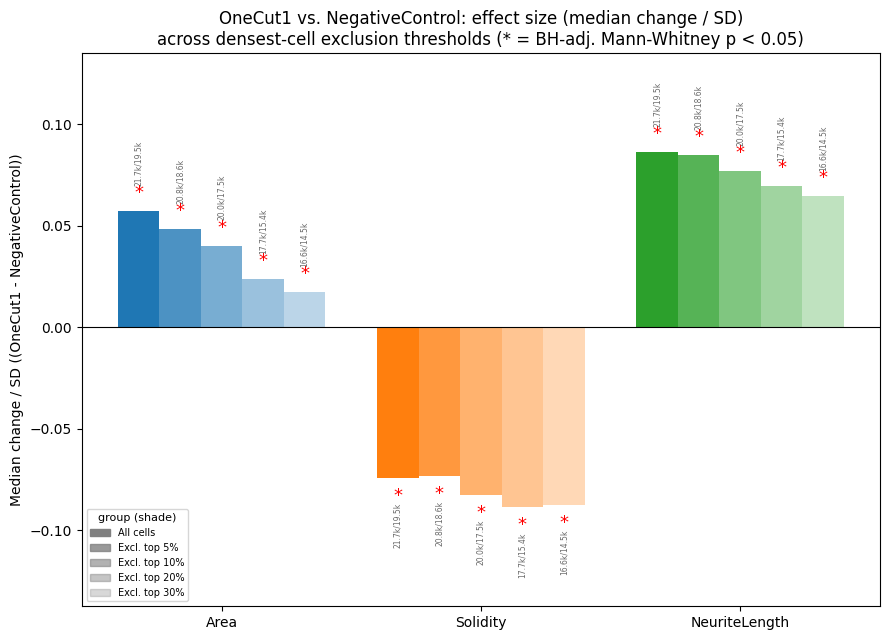

In [9]:
METRIC_COLOR_3 = {"AreaShape_Area": "#1f77b4", "AreaShape_Solidity": "#ff7f0e", "Skeleton_TotalLength_neurite": "#2ca02c"}
EXCL_GROUPS = [(0, "All cells"), (5, "Excl. top 5%"), (10, "Excl. top 10%"), (20, "Excl. top 20%"), (30, "Excl. top 30%")]
EXCL_ALPHA = [1.0, 0.8, 0.6, 0.45, 0.3]

def excl_group_data(ex_pct):
    keep_pct = 100 - ex_pct
    cutoff = pert["neighbor_count"].quantile(keep_pct / 100) if keep_pct < 100 else pert["neighbor_count"].max()
    sub = pert[pert["neighbor_count"] <= cutoff]
    t_df = sub[sub.group == TREATMENT_KEY]
    c_df = sub[sub.group == "Ctrl"]
    return t_df, c_df

def median_sd_effect(metrics_list):
    rows = []
    for ex_pct, label in EXCL_GROUPS:
        t_df, c_df = excl_group_data(ex_pct)
        recs = []
        for m in metrics_list:
            t = t_df[m].dropna().to_numpy(); c = c_df[m].dropna().to_numpy()
            _, u_p = mannwhitneyu(t, c, alternative="two-sided")
            med_t, med_c = np.median(t), np.median(c)
            eff = (med_t - med_c) / np.concatenate([t, c]).std()
            recs.append({"metric": m, "eff": eff, "u_p_raw": u_p, "n_t": len(t), "n_c": len(c)})
        u_adj = multipletests([r["u_p_raw"] for r in recs], alpha=ALPHA, method="fdr_bh")[1]
        for r, p in zip(recs, u_adj):
            r["u_p_adj"] = p; r["excluded_pct"] = ex_pct; r["group_label"] = label
        rows.extend(recs)
    return pd.DataFrame(rows)

def density_exclusion_barplot(metrics_list, fname, figsize):
    df = median_sd_effect(metrics_list)
    fig, ax = plt.subplots(figsize=figsize)
    n_m = len(metrics_list)
    n_g = len(EXCL_GROUPS)
    width = 0.8 / n_g
    x = np.arange(n_m)
    span = max(1e-6, df["eff"].abs().max())
    for i, (ex_pct, label) in enumerate(EXCL_GROUPS):
        sub = df[df.excluded_pct == ex_pct].set_index("metric").loc[metrics_list]
        xpos = x + (i - (n_g - 1) / 2) * width
        colors = [METRIC_COLOR_3[m] for m in metrics_list]
        ax.bar(xpos, sub["eff"], width=width, color=colors, alpha=EXCL_ALPHA[i],
               label=label if i == 0 else None, edgecolor="none")
        for xi, (m, row) in zip(xpos, sub.iterrows()):
            y = row["eff"]
            sign = np.sign(y) if y != 0 else 1
            ax.text(xi, y + sign * 0.14 * span, f"{row['n_t']/1000:.1f}k/{row['n_c']/1000:.1f}k", ha="center",
                    va="bottom" if y >= 0 else "top", fontsize=5.5, rotation=90, color="dimgray")
            if row["u_p_adj"] < ALPHA:
                ax.text(xi, y + sign * 0.05 * span, "*", ha="center",
                        va="bottom" if y >= 0 else "top", color="red", fontsize=13)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x); ax.set_xticklabels([METRIC_SHORT[m] for m in metrics_list])
    ax.set_ylabel(f"Median change / SD (({LABEL[TREATMENT_KEY]} - {LABEL['Ctrl']}))")
    ax.set_ylim(df["eff"].min() - 0.55 * span, df["eff"].max() + 0.55 * span)
    ax.set_title(f"{LABEL[TREATMENT_KEY]} vs. NegativeControl: effect size (median change / SD)\nacross densest-cell exclusion thresholds (* = BH-adj. Mann-Whitney p < 0.05)")
    handles = [plt.Rectangle((0, 0), 1, 1, color="gray", alpha=a) for a in EXCL_ALPHA]
    ax.legend(handles, [lab for _, lab in EXCL_GROUPS], title="group (shade)", fontsize=7, title_fontsize=8, loc="best")
    plt.tight_layout()
    savefig(fig, "median_stdeffect_by_exclusion_3metric")
    plt.show()

density_exclusion_barplot(METRICS_3, "median_stdeffect_by_exclusion_3metric", (9, 6.5))

## Neighbor-count distribution with the exclusion cutoffs

Same neighbor-count distribution for BFP-positive cells in both conditions, with the four densest-cell exclusion thresholds used above marked.

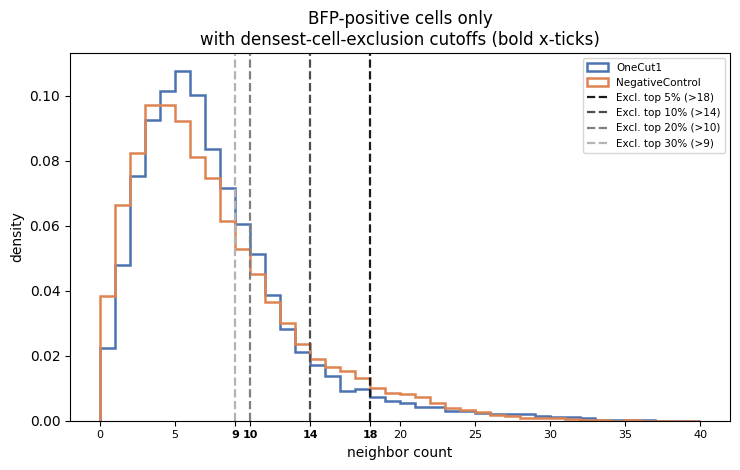

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for g in GROUPS:
    ax.hist(pert.loc[pert.group == g, "neighbor_count"], bins=range(0, 41), histtype="step", density=True,
            color=COLOR[g], label=LABEL[g], lw=1.8)

excl_levels = [(5, "Excl. top 5%"), (10, "Excl. top 10%"), (20, "Excl. top 20%"), (30, "Excl. top 30%")]
line_shades = ["#1a1a1a", "#4d4d4d", "#808080", "#b3b3b3"]
cutoffs = []
for (pct, label), lc in zip(excl_levels, line_shades):
    cutoff = pert["neighbor_count"].quantile((100 - pct) / 100)
    cutoffs.append(cutoff)
    ax.axvline(cutoff, color=lc, ls="--", lw=1.6, label=f"{label} (>{cutoff:.0f})")

cutoff_ints = {int(round(c)) for c in cutoffs}
xticks = sorted({t for t in range(0, 41, 5) if all(abs(t - c) > 1 for c in cutoff_ints)} | cutoff_ints)
ax.set_xticks(xticks)
ax.tick_params(axis="x", labelsize=8)
for lbl in ax.get_xticklabels():
    if int(float(lbl.get_text())) in cutoff_ints:
        lbl.set_fontweight("bold")

ax.set_xlabel("neighbor count"); ax.set_ylabel("density")
ax.set_title("BFP-positive cells only\nwith densest-cell-exclusion cutoffs (bold x-ticks)")
ax.legend(fontsize=7.5, loc="upper right")
plt.tight_layout()
savefig(fig, "neighbor_count_distribution_exclusion_cutoffs")
plt.show()